In [26]:

import pandas as pd
import matplotlib.pyplot as plt

# Load cleaned NWSL datasets from GitHub
players_url = "https://raw.githubusercontent.com/leaaa2000/NWSL-Performance-Analytics/main/data/cleaned/nwsl_players_cleaned.csv"
teams_url = "https://raw.githubusercontent.com/leaaa2000/NWSL-Performance-Analytics/main/data/cleaned/nwsl_teams_cleaned.csv"

players = pd.read_csv(players_url)
teams = pd.read_csv(teams_url)

print("Player records:", players.shape)
print("Team records:", teams.shape)

display(players.head())
display(teams.head())


Player records: (15696, 13)
Team records: (890, 9)


,game_id,season,team_id,player_id,first_name,last_name,position,goals,goal_assist,total_shots,total_pass,accurate_pass,player_name
0,portland-thorns-vs-houston-dash-2016-09-07,2016,POR,9ifjrfggioh9cmphk85gykzx1,Michelle,Betos,Goalkeeper,0,0,0,41,35,Michelle Betos
1,portland-thorns-vs-houston-dash-2016-09-07,2016,POR,bnnc9csv7qrc2xgx7yzgxlcr9,Meghan,Klingenberg,Defender,0,0,1,42,36,Meghan Klingenberg
2,portland-thorns-vs-houston-dash-2016-09-07,2016,POR,5zwpytehpeosi3sfckvkuy3md,Emily,Menges,Defender,0,0,0,64,58,Emily Menges
3,portland-thorns-vs-houston-dash-2016-09-07,2016,POR,3aj7p478dcuat6tz8096sq8dl,Emily,Sonnett,Defender,0,0,1,67,57,Emily Sonnett
4,portland-thorns-vs-houston-dash-2016-09-07,2016,POR,2usg5n5edeznax3nybdta11x,Katherine,Reynolds,Defender,0,0,0,32,24,Katherine Reynolds


,game_id,season,status,team,goals,goal_assist,total_shots,total_pass,accurate_pass
0,portland-thorns-vs-houston-dash-2016-09-07,2016,home,POR,3,2,21,545,464
1,portland-thorns-vs-houston-dash-2016-09-07,2016,away,HOU,0,0,8,394,298
2,western-new-york-flash-vs-kansas-city-2016-07-23,2016,home,WNY,0,0,22,301,206
3,western-new-york-flash-vs-kansas-city-2016-07-23,2016,away,KC,1,1,11,230,125
4,western-new-york-flash-vs-houston-dash-2016-08-27,2016,home,WNY,2,2,14,393,278


In [27]:

# Top 10 goal scorers
top_scorers = (
    players.groupby(["player_id", "player_name"], as_index=False)["goals"]
    .sum()
    .sort_values("goals", ascending=False)
    .head(10)
)

display(top_scorers)



,player_id,player_name,goals
178,66f0rjs4c2yih8phn6meyj74l,Sam Kerr,57
356,cm6fzm8v38ti0aubu0q4v717t,Lynn Williams,48
349,cfx9wllh2x6ozkvqxusa3sl3p,Christine Sinclair,34
329,bnxnrws4yintb6s76erzl9xw5,Christen Press,30
51,2qqged8hw4lzh6u8r81kc22fp,Jessica McDonald,30
202,6ywkny98b9qzuvhqxwn9l0ogl,Lindsey Horan,26
397,dwwgrimn3ddecp5kllvsdga8l,Sofia Huerta,26
301,amg2zai9038cdz9uuql3l9rkl,Rachel Daly,24
153,5ekbwy8vf1l1jzj6txawrg7h1,Debinha,23
338,c811si1xw5he6ih0o1mj94tsl,Marta,23


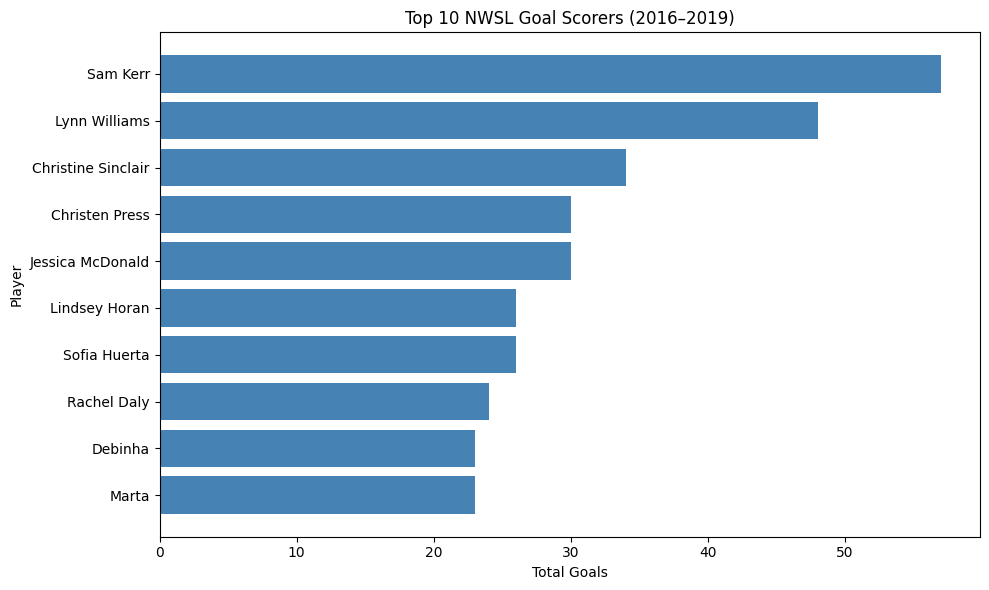

In [28]:

# Plot the top 10 goal scorers
plt.figure(figsize=(10, 6))

plt.barh(top_scorers["player_name"], top_scorers["goals"], color="steelblue")

plt.xlabel("Total Goals")
plt.ylabel("Player")
plt.title("Top 10 NWSL Goal Scorers (2016–2019)")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [29]:

# Top 10 players by assists
top_assists = (
    players.groupby(["player_id", "player_name"], as_index=False)["goal_assist"]
    .sum()
    .sort_values("goal_assist", ascending=False)
    .head(10)
)

display(top_assists)


,player_id,player_name,goal_assist
356,cm6fzm8v38ti0aubu0q4v717t,Lynn Williams,22
51,2qqged8hw4lzh6u8r81kc22fp,Jessica McDonald,22
365,cxl4bxs35ifb8o5cq9jxi1ec5,Tobin Heath,21
362,csx5jhf4hyzld6gg790usp0wl,Yuki Nagasato,17
397,dwwgrimn3ddecp5kllvsdga8l,Sofia Huerta,16
92,4b13osk9pzrosvzqt55y7o34l,Crystal Dunn,16
201,6yewao79nhfa4fct6bqfw5bdh,Jaelene Hinkle,16
218,7flxdnsd0pp5nxhldypcxeled,Nahomi Kawasumi,15
113,4tgpaf43xg2ehk4u4bkt8k2c5,Christine Nairn,14
328,bnnc9csv7qrc2xgx7yzgxlcr9,Meghan Klingenberg,13


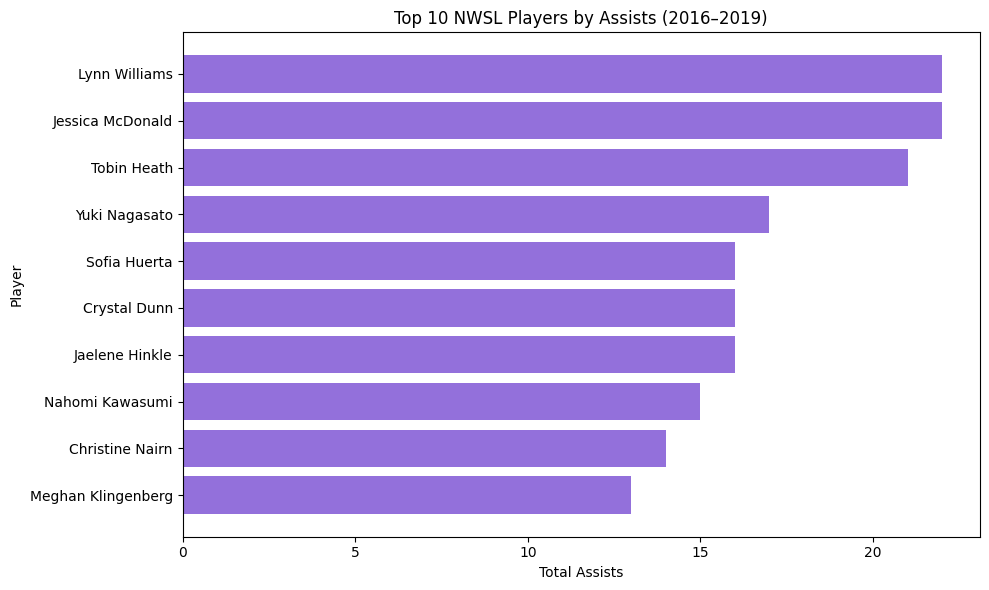

In [30]:

# Plot top 10 assists
plt.figure(figsize=(10, 6))

plt.barh(
    top_assists["player_name"],
    top_assists["goal_assist"],
    color="mediumpurple"
)

plt.xlabel("Total Assists")
plt.ylabel("Player")
plt.title("Top 10 NWSL Players by Assists (2016–2019)")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("top_assists.png", dpi=300, bbox_inches="tight")
plt.show()


In [31]:

# Total goals by team
team_goals = (
    teams.groupby("team", as_index=False)["goals"]
    .sum()
    .sort_values("goals", ascending=False)
)

display(team_goals)


,team,goals
7,POR,162
4,NC,158
1,CHI,136
8,SEA,127
6,ORL,120
2,HOU,108
5,NJ,106
10,WAS,106
9,UTA,47
11,WNY,46


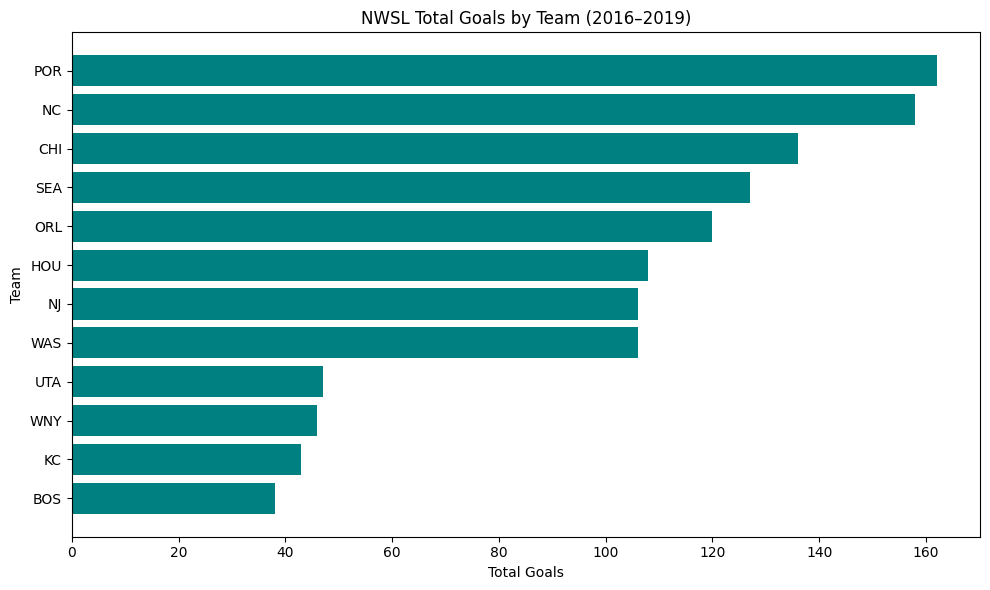

In [32]:

# Plot team goals
plt.figure(figsize=(10, 6))

plt.barh(team_goals["team"], team_goals["goals"], color="teal")

plt.xlabel("Total Goals")
plt.ylabel("Team")
plt.title("NWSL Total Goals by Team (2016–2019)")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [33]:

# Average goals per match by team
team_avg_goals = (
    teams.groupby("team")
    .agg(
        total_goals=("goals", "sum"),
        matches_played=("goals", "count")
    )
    .reset_index()
)

team_avg_goals["goals_per_match"] = (
    team_avg_goals["total_goals"] / team_avg_goals["matches_played"]
)

team_avg_goals = team_avg_goals.sort_values(
    "goals_per_match", ascending=False
)

display(team_avg_goals)


,team,total_goals,matches_played,goals_per_match
11,WNY,46,22,2.090909
4,NC,158,77,2.051948
7,POR,162,98,1.653061
1,CHI,136,96,1.416667
8,SEA,127,93,1.365591
6,ORL,120,93,1.290323
2,HOU,108,91,1.186813
5,NJ,106,91,1.164835
10,WAS,106,94,1.127660
3,KC,43,43,1.000000


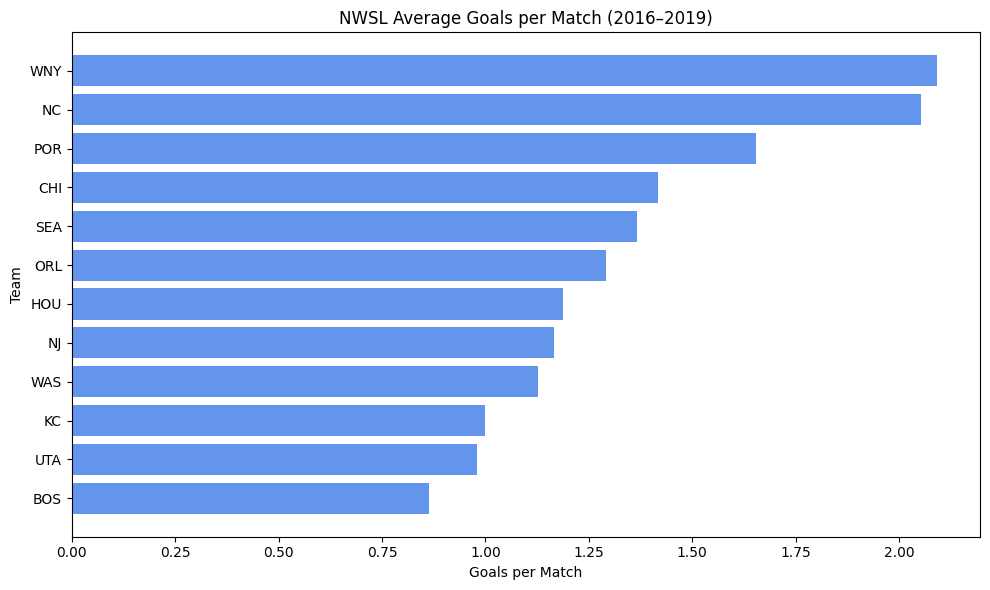

In [34]:

# Plot average goals per match
plt.figure(figsize=(10, 6))

plt.barh(
    team_avg_goals["team"],
    team_avg_goals["goals_per_match"],
    color="cornflowerblue"
)

plt.xlabel("Goals per Match")
plt.ylabel("Team")
plt.title("NWSL Average Goals per Match (2016–2019)")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [35]:

# Team passing accuracy
team_passing = (
    teams.groupby("team")
    .agg(
        total_passes=("total_pass", "sum"),
        accurate_passes=("accurate_pass", "sum"),
        matches_with_data=("total_pass", "count")
    )
    .reset_index()
)

team_passing = team_passing[team_passing["total_passes"] > 0].copy()

team_passing["passing_accuracy"] = (
    team_passing["accurate_passes"] /
    team_passing["total_passes"] * 100
)

team_passing = team_passing.sort_values(
    "passing_accuracy", ascending=False
)

display(team_passing)


,team,total_passes,accurate_passes,matches_with_data,passing_accuracy
9,UTA,22352,16997,48,76.042412
8,SEA,40818,29939,93,73.347543
6,ORL,37467,27453,93,73.272480
5,NJ,36665,26820,91,73.148779
2,HOU,35802,26170,91,73.096475
3,KC,16913,12317,43,72.825637
10,WAS,39709,28865,94,72.691329
4,NC,30785,22249,77,72.272210
7,POR,39925,28785,98,72.097683
1,CHI,37711,26538,96,70.372040


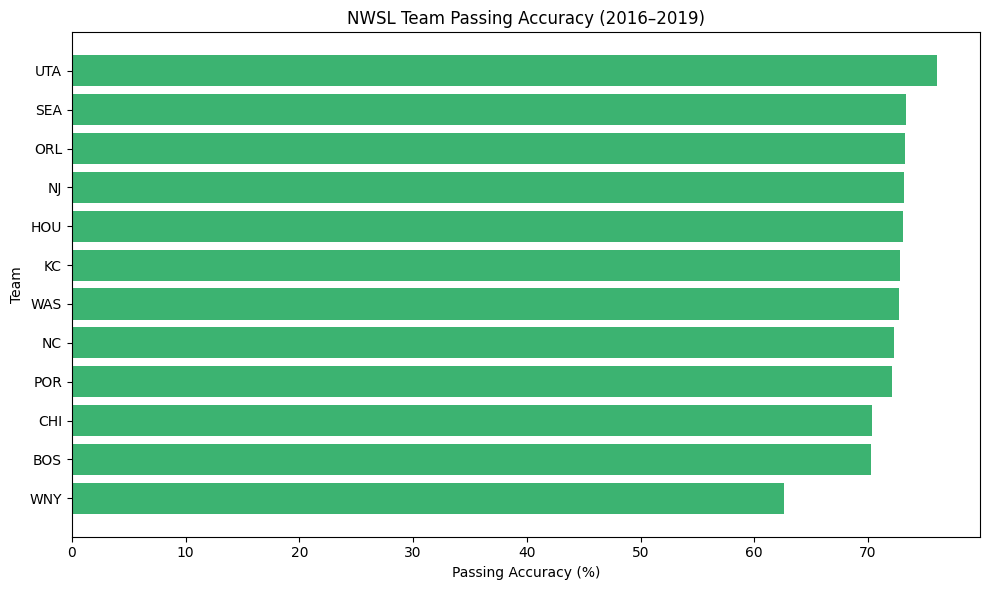

In [36]:

# Plot passing accuracy
plt.figure(figsize=(10, 6))

plt.barh(
    team_passing["team"],
    team_passing["passing_accuracy"],
    color="mediumseagreen"
)

plt.xlabel("Passing Accuracy (%)")
plt.ylabel("Team")
plt.title("NWSL Team Passing Accuracy (2016–2019)")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [37]:

# Total goals by season
season_goals = (
    teams.groupby("season", as_index=False)["goals"]
    .sum()
    .sort_values("season")
)

display(season_goals)


,season,goals
0,2016,277
1,2017,342
2,2018,286
3,2019,292


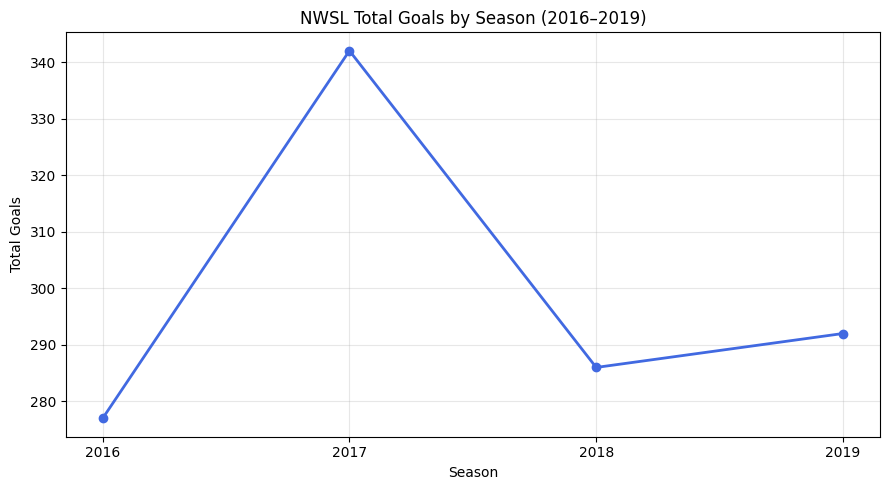

In [38]:

# Plot seasonal goals
plt.figure(figsize=(9, 5))

plt.plot(
    season_goals["season"].astype(str),
    season_goals["goals"],
    marker="o",
    color="royalblue",
    linewidth=2
)

plt.xlabel("Season")
plt.ylabel("Total Goals")
plt.title("NWSL Total Goals by Season (2016–2019)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [39]:

# Check goals for each game
game_check = teams.groupby("game_id").agg(
    team_count=("team", "count"),
    goal_count=("goals", "count")
).reset_index()

# Keep complete games
valid_games = game_check[
    (game_check["team_count"] == 2) &
    (game_check["goal_count"] == 2)
]

complete_teams = teams[
    teams["game_id"].isin(valid_games["game_id"])
]

# Calculate seasonal averages
season_summary = complete_teams.groupby("season").agg(
    total_goals=("goals", "sum"),
    team_records=("game_id", "count")
).reset_index()

season_summary["matches"] = season_summary["team_records"] / 2

season_summary["goals_per_match"] = (
    season_summary["total_goals"] / season_summary["matches"]
)

display(season_summary)


,season,total_goals,team_records,matches,goals_per_match
0,2016,277,206,103.0,2.689320
1,2017,342,240,120.0,2.850000
2,2018,286,222,111.0,2.576577
3,2019,292,222,111.0,2.630631


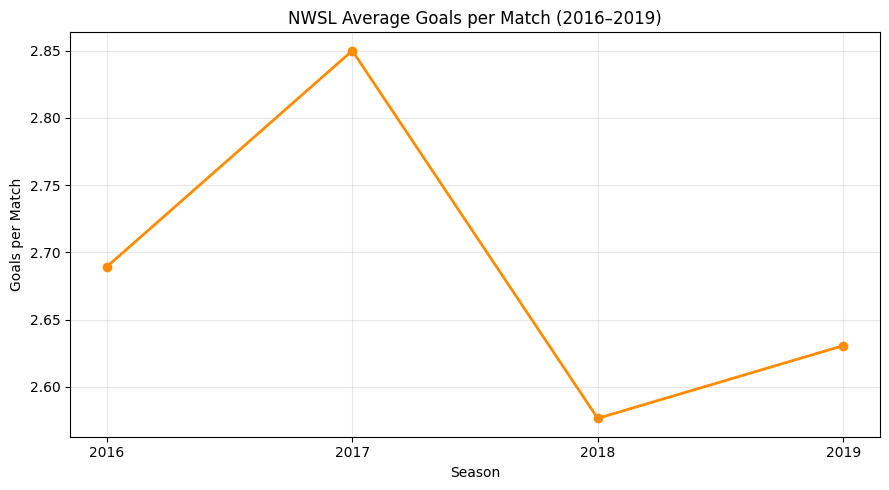

In [40]:

# Plot seasonal goals per match
plt.figure(figsize=(9, 5))

plt.plot(
    season_summary["season"].astype(str),
    season_summary["goals_per_match"],
    marker="o",
    color="darkorange",
    linewidth=2
)

plt.xlabel("Season")
plt.ylabel("Goals per Match")
plt.title("NWSL Average Goals per Match (2016–2019)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("season_avg_goals.png", dpi=300, bbox_inches="tight")
plt.show()


In [41]:

# Check missing team stats
print("Missing team values:")
print(teams[["goals", "total_shots", "total_pass", "accurate_pass"]].isna().sum())

# Check team records per game
match_counts = teams.groupby("game_id").size()

print("\nGames with missing or extra team records:")
print(match_counts[match_counts != 2])

# Check games with complete goal data
complete_goals = teams.groupby("game_id")["goals"].count()
print("\nGames with complete goal data:", (complete_goals == 2).sum())


Missing team values:
goals            0
total_shots      0
total_pass       0
accurate_pass    0
dtype: int64

Games with missing or extra team records:
Series([], dtype: int64)

Games with complete goal data: 445


In [42]:

# Count team records and goals for each game
game_check = teams.groupby("game_id").agg(
    team_count=("team", "count"),
    goal_count=("goals", "count")
).reset_index()

# Keep games with complete goal data
valid_games = game_check[
    (game_check["team_count"] == 2) &
    (game_check["goal_count"] == 2)
]

# Get the team records for those games
complete_teams = teams[
    teams["game_id"].isin(valid_games["game_id"])
]

# Calculate goals by season
season_summary = complete_teams.groupby("season").agg(
    total_goals=("goals", "sum"),
    team_records=("game_id", "count")
).reset_index()

season_summary["matches"] = season_summary["team_records"] / 2

season_summary["goals_per_match"] = (
    season_summary["total_goals"] / season_summary["matches"]
)

display(season_summary)


,season,total_goals,team_records,matches,goals_per_match
0,2016,277,206,103.0,2.689320
1,2017,342,240,120.0,2.850000
2,2018,286,222,111.0,2.576577
3,2019,292,222,111.0,2.630631


In [43]:

# Save analysis results
top_scorers.to_csv("top_scorers.csv", index=False)
top_assists.to_csv("top_assists.csv", index=False)
team_goals.to_csv("team_goals.csv", index=False)
team_avg_goals.to_csv("team_avg_goals.csv", index=False)
team_passing.to_csv("team_passing.csv", index=False)
season_summary.to_csv("season_summary.csv", index=False)

print("Analysis tables saved!")


Analysis tables saved!


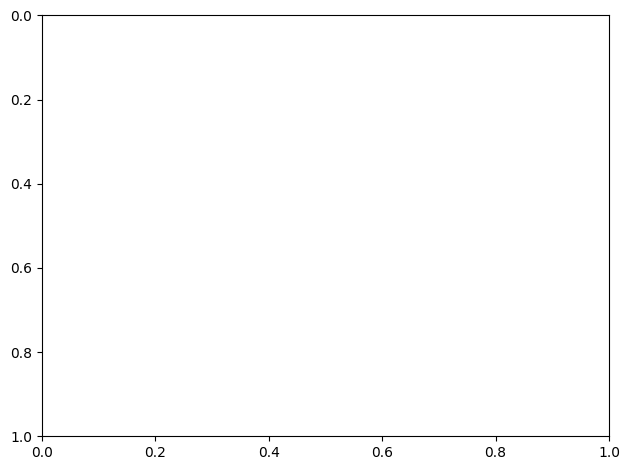

In [44]:

plt.gca().invert_yaxis()
plt.tight_layout()

# Save graph
plt.savefig("team_passing_accuracy.png", dpi=300, bbox_inches="tight")

plt.show()
